In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Campaigns Dataset

In [2]:
df = pd.read_csv('C:/Users/raval/OneDrive/Desktop/Data Analysis Project/campaigns.csv')

In [3]:
df.head()

,campaign_id,channel,objective,start_date,end_date,target_segment,expected_uplift
0,1,Paid Search,Cross-sell,2021-10-25,2021-11-26,Deal Seekers,0.022
1,2,Email,Retention,2021-10-24,2021-12-24,Deal Seekers,0.116
2,3,Email,Reactivation,2023-10-08,2023-11-30,Churn Risk,0.100
3,4,Display,Reactivation,2022-07-25,2022-10-07,Deal Seekers,0.111
4,5,Social,Acquisition,2022-07-09,2022-09-29,New Customers,0.144


In [4]:
df.tail()

,campaign_id,channel,objective,start_date,end_date,target_segment,expected_uplift
45,46,Social,Cross-sell,2023-03-23,2023-04-17,All,0.030
46,47,Affiliate,Cross-sell,2022-04-12,2022-06-04,High Value,0.066
47,48,Paid Search,Acquisition,2022-01-05,2022-04-04,New Customers,0.099
48,49,Paid Search,Reactivation,2021-04-09,2021-05-24,Deal Seekers,0.128
49,50,Email,Retention,2021-02-14,2021-03-24,Churn Risk,0.023


In [5]:
df.shape

(50, 7)

In [6]:
df.describe()

,campaign_id,expected_uplift
count,50.00000,50.000000
mean,25.50000,0.086660
std,14.57738,0.035854
min,1.00000,0.022000
25%,13.25000,0.057250
50%,25.50000,0.092500
75%,37.75000,0.113750
max,50.00000,0.144000


In [7]:
df['start_date'] = pd.to_datetime(df['start_date'])
df['end_date'] = pd.to_datetime(df['end_date'])

In [8]:
df.nunique()

campaign_id        50
channel             5
objective           4
start_date         49
end_date           48
target_segment      5
expected_uplift    43
dtype: int64

In [9]:
df['channel'].unique()

array(['Paid Search', 'Email', 'Display', 'Social', 'Affiliate'],
      dtype=object)

In [10]:
df['objective'].unique()

array(['Cross-sell', 'Retention', 'Reactivation', 'Acquisition'],
      dtype=object)

In [11]:
df['target_segment'].unique()

array(['Deal Seekers', 'Churn Risk', 'New Customers', 'High Value', 'All'],
      dtype=object)

In [12]:
df.isnull().sum()

campaign_id        0
channel            0
objective          0
start_date         0
end_date           0
target_segment     0
expected_uplift    0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

Outlier Detection with Boxplot

<Axes: >

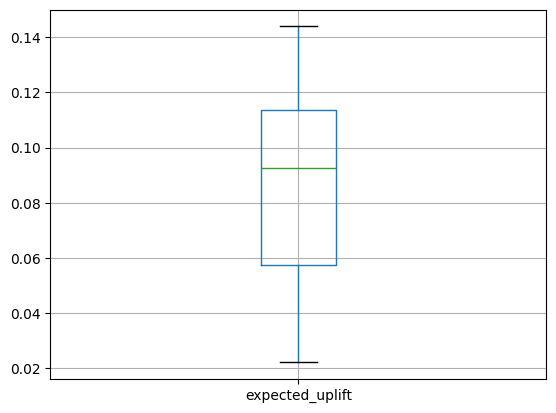

In [14]:
df.boxplot(column='expected_uplift')

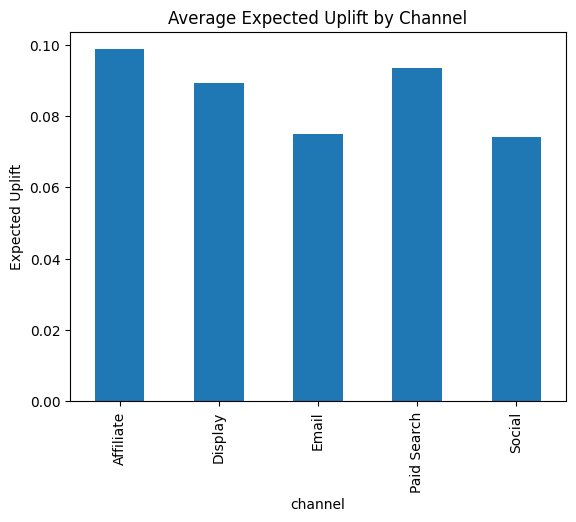

In [15]:
df.groupby('channel')['expected_uplift'].mean().plot(
    kind='bar')

plt.title('Average Expected Uplift by Channel')
plt.ylabel('Expected Uplift')
plt.show()

Customers Dataset

In [16]:
df1 = pd.read_csv('C:/Users/raval/OneDrive/Desktop/Data Analysis Project/customers.csv')

In [17]:
df1.head()

,customer_id,signup_date,country,age,gender,loyalty_tier,acquisition_channel
0,1,2021-04-08,BR,48,Male,Bronze,Referral
1,2,2023-04-28,IN,36,Female,Silver,Organic
2,3,2022-12-18,UK,35,Female,Silver,Organic
3,4,2022-04-26,US,45,Male,Silver,Paid Search
4,5,2022-04-20,IN,53,Male,Silver,Organic


In [18]:
df1.shape

(100000, 7)

In [19]:
df1['signup_date'] = pd.to_datetime(df1['signup_date'])

In [20]:
df1.nunique()

customer_id            100000
signup_date              1095
country                     7
age                        53
gender                      3
loyalty_tier                4
acquisition_channel         5
dtype: int64

In [21]:
df1['country'].unique()

array(['BR', 'IN', 'UK', 'US', 'CA', 'AU', 'DE'], dtype=object)

In [22]:
df1['gender'].unique()

array(['Male', 'Female', 'Other'], dtype=object)

In [23]:
df1['loyalty_tier'].unique()

array(['Bronze', 'Silver', 'Gold', 'Platinum'], dtype=object)

In [24]:
df1['acquisition_channel'].unique()

array(['Referral', 'Organic', 'Paid Search', 'Social', 'Email'],
      dtype=object)

In [25]:
df1.describe()

,customer_id,signup_date,age
count,100000.000000,100000,100000.000000
mean,50000.500000,2022-07-01 20:16:26.400000,35.224370
min,1.000000,2021-01-01 00:00:00,18.000000
25%,25000.750000,2021-10-01 00:00:00,28.000000
50%,50000.500000,2022-07-03 00:00:00,35.000000
75%,75000.250000,2023-04-01 00:00:00,42.000000
max,100000.000000,2023-12-31 00:00:00,70.000000
std,28867.657797,NaN,9.595792


In [26]:
df1.isnull().sum()

customer_id            0
signup_date            0
country                0
age                    0
gender                 0
loyalty_tier           0
acquisition_channel    0
dtype: int64

In [27]:
df1.duplicated().sum()

np.int64(0)

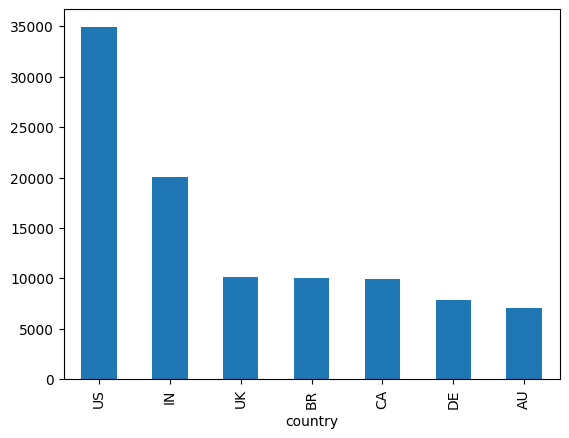

In [28]:
df1['country'].value_counts().plot(kind='bar')
plt.show()

Events Dataset

In [29]:
df2 = pd.read_csv('C:/Users/raval/OneDrive/Desktop/Data Analysis Project/events.csv')

In [30]:
df2.head()

,event_id,timestamp,customer_id,session_id,event_type,product_id,device_type,traffic_source,campaign_id,page_category,session_duration_sec,experiment_group
0,1,2021-01-14 13:35:43,43812,535101,view,1004.0,desktop,Email,43,PLP,115.1,Control
1,2,2021-12-03 21:36:50,71340,96426,add_to_cart,986.0,desktop,Email,10,PDP,32.4,Variant_A
2,3,2021-12-27 08:25:15,59540,220126,purchase,1630.0,mobile,Organic,0,PDP,190.7,Variant_A
3,4,2022-01-22 15:06:54,3601,484555,add_to_cart,1532.0,desktop,Paid Search,30,Checkout,134.8,Variant_B
4,5,2021-05-10 12:03:09,92735,60646,bounce,NaN,desktop,Email,26,PLP,53.1,Variant_A


In [31]:
df2.shape

(2000000, 12)

In [32]:
df2['timestamp'] = pd.to_datetime(df2['timestamp'])

In [33]:
df2.nunique()

event_id                2000000
timestamp               1977065
customer_id              100000
session_id               633462
event_type                    5
product_id                 2000
device_type                   3
traffic_source               10
campaign_id                  51
page_category                 5
session_duration_sec      16524
experiment_group              3
dtype: int64

In [34]:
df2['event_type'].unique()

array(['view', 'add_to_cart', 'purchase', 'bounce', 'click'], dtype=object)

In [35]:
df2['device_type'].unique()

array(['desktop', 'mobile', 'tablet', nan], dtype=object)

In [36]:
df2['page_category'].unique()

array(['PLP', 'PDP', 'Checkout', 'Home', 'Cart'], dtype=object)

In [37]:
df2['experiment_group'].unique()

array(['Control', 'Variant_A', 'Variant_B'], dtype=object)

In [38]:
df2['traffic_source'].unique()

array(['Email', 'Organic', 'Paid Search', 'Social', 'Direct',
       'PAID SEARCH', 'DIRECT', 'EMAIL', 'ORGANIC', 'SOCIAL'],
      dtype=object)

In [39]:
df2['traffic_source'] = df2['traffic_source'].str.strip().str.title()
df2['traffic_source'].unique()

array(['Email', 'Organic', 'Paid Search', 'Social', 'Direct'],
      dtype=object)

In [40]:
df2['traffic_source'].nunique()

5

In [41]:
df2['campaign_id'].unique()

array([43, 10,  0, 30, 26,  8, 21,  7, 48,  9, 31, 37, 32, 50, 13,  6, 12,
       24, 22, 14, 18, 25, 49, 38,  4, 39, 40,  2, 47, 36,  1, 28,  5, 45,
       44, 29,  3, 27, 23, 20, 19, 35, 17, 11, 15, 46, 42, 34, 16, 41, 33])

In [42]:
df2.isnull().sum()

event_id                     0
timestamp                    0
customer_id                  0
session_id                   0
event_type                   0
product_id              200371
device_type              40300
traffic_source               0
campaign_id                  0
page_category                0
session_duration_sec         0
experiment_group             0
dtype: int64

In [43]:
df2['device_type'] = df2['device_type'].fillna('Unknown')

In [44]:
df2.isnull().sum()

event_id                     0
timestamp                    0
customer_id                  0
session_id                   0
event_type                   0
product_id              200371
device_type                  0
traffic_source               0
campaign_id                  0
page_category                0
session_duration_sec         0
experiment_group             0
dtype: int64

In [45]:
df2.duplicated().sum()

np.int64(0)

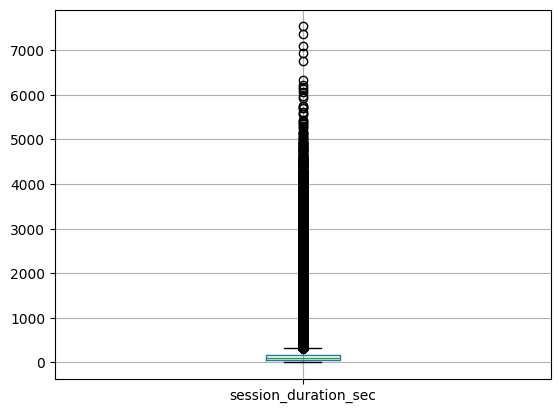

In [46]:
df2.boxplot(column='session_duration_sec')
plt.show()

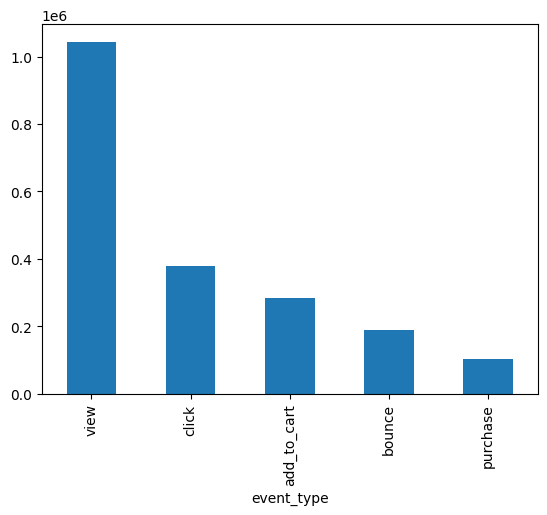

In [47]:
df2['event_type'].value_counts().plot(kind='bar')
plt.show()

Products Dataset

In [48]:
df3 = pd.read_csv('C:/Users/raval/OneDrive/Desktop/Data Analysis Project/products.csv')

In [49]:
df3.head()

,product_id,category,brand,base_price,launch_date,is_premium
0,1,Grocery,Brand_58,14.19,2021-08-02,0
1,2,Fashion,Brand_1,25.80,2021-09-14,0
2,3,Electronics,Brand_70,165.46,2021-01-18,1
3,4,Fashion,Brand_56,75.45,2023-03-03,1
4,5,Sports,Brand_1,72.50,2022-04-19,1


In [50]:
df3['launch_date'] = pd.to_datetime(df3['launch_date'])

In [51]:
df3.nunique()

product_id     2000
category          6
brand           100
base_price     1869
launch_date     901
is_premium        2
dtype: int64

In [52]:
df3.shape

(2000, 6)

In [53]:
df3['category'].unique()

array(['Grocery', 'Fashion', 'Electronics', 'Sports', 'Beauty', 'Home'],
      dtype=object)

In [54]:
df3['is_premium'].unique()

array([0, 1])

In [55]:
df3.isnull().sum()

product_id     0
category       0
brand          0
base_price     0
launch_date    0
is_premium     0
dtype: int64

In [56]:
df3.duplicated().sum()

np.int64(0)

In [57]:
df3.describe()

,product_id,base_price,launch_date,is_premium
count,2000.000000,2000.000000,2000,2000.000000
mean,1000.500000,72.166650,2022-06-27 07:50:52.800000,0.500000
min,1.000000,5.110000,2021-01-01 00:00:00,0.000000
25%,500.750000,32.505000,2021-09-26 00:00:00,0.000000
50%,1000.500000,61.245000,2022-06-18 00:00:00,0.500000
75%,1500.250000,97.955000,2023-03-22 00:00:00,1.000000
max,2000.000000,464.580000,2023-12-31 00:00:00,1.000000
std,577.494589,52.315792,NaN,0.500125


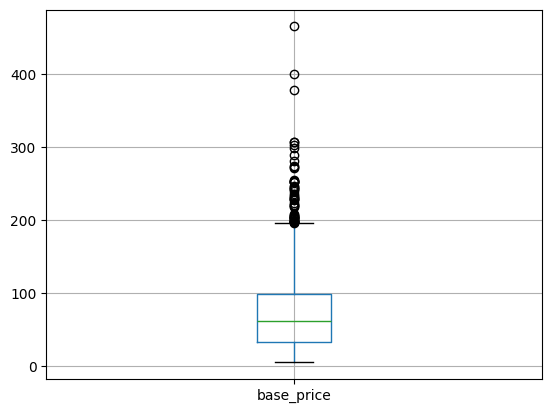

In [58]:
df3.boxplot(column='base_price')
plt.show()

Transactions Dataset

In [59]:
df4 = pd.read_csv('C:/Users/raval/OneDrive/Desktop/Data Analysis Project/transactions.csv')

In [60]:
df4.head()

,transaction_id,timestamp,customer_id,product_id,quantity,discount_applied,gross_revenue,campaign_id,refund_flag
0,1,2021-12-27 08:25:15,59540,1630.0,3,0.00,43.74,0,0
1,2,2023-06-06 21:14:26,54871,1901.0,3,0.00,174.78,21,0
2,3,2023-08-31 05:29:54,51818,1884.0,1,0.00,40.61,37,0
3,4,2022-06-26 20:33:46,18164,1114.0,2,0.15,68.76,13,0
4,5,2023-07-26 18:12:35,86915,408.0,1,0.00,14.64,4,0


In [61]:
df4.shape

(103127, 9)

In [62]:
df4['timestamp'] = pd.to_datetime(df4['timestamp'])

In [63]:
df4['refund_flag'].unique()

array([0, 1])

In [64]:
df4.isnull().sum()

transaction_id          0
timestamp               0
customer_id             0
product_id          10449
quantity                0
discount_applied        0
gross_revenue       10449
campaign_id             0
refund_flag             0
dtype: int64

In [65]:
df4['gross_revenue'].describe()

count    92678.000000
mean        90.355493
std        100.684683
min       -783.040000
25%         34.240000
50%         68.000000
75%        117.617500
max       1858.320000
Name: gross_revenue, dtype: float64

In [66]:
df4['gross_revenue'].skew()

np.float64(2.4745631297736006)

In [67]:
df4[df4['gross_revenue'] < 0]

,transaction_id,timestamp,customer_id,product_id,quantity,discount_applied,gross_revenue,campaign_id,refund_flag
11,12,2021-04-04 21:06:51,69122,781.0,1,0.20,-97.41,30,1
19,20,2023-07-31 13:11:49,30583,899.0,1,0.00,-176.65,4,1
87,88,2023-01-25 20:28:58,42213,1709.0,1,0.10,-46.32,9,1
169,170,2023-04-10 19:53:23,12388,154.0,2,0.10,-85.23,8,1
249,250,2023-07-02 06:12:13,56791,732.0,1,0.05,-121.87,49,1
...,...,...,...,...,...,...,...,...,...
102985,102986,2023-11-27 10:07:29,78507,869.0,1,0.00,-146.36,31,1
102994,102995,2022-01-09 11:23:50,64955,463.0,2,0.00,-46.44,40,1
103069,103070,2022-03-01 13:44:11,31971,34.0,1,0.00,-58.08,4,1
103086,103087,2021-09-11 17:30:09,29151,900.0,1,0.00,-106.95,0,1


In [68]:
missing_rows = df4[df4['product_id'].isnull() | df4['gross_revenue'].isnull()]

In [69]:
print(missing_rows)

        transaction_id           timestamp  customer_id  product_id  quantity  \
15                  16 2021-02-13 07:36:17        33154         NaN         1   
20                  21 2023-03-29 19:49:38        52652         NaN         1   
21                  22 2021-08-01 15:47:25        30425         NaN         1   
55                  56 2023-06-13 04:11:11         1280         NaN         3   
57                  58 2022-07-23 20:38:49        32032         NaN         1   
...                ...                 ...          ...         ...       ...   
103042          103043 2021-11-21 10:13:36        97202         NaN         1   
103066          103067 2023-06-09 08:45:34        22073         NaN         1   
103096          103097 2022-01-05 02:47:16        44512         NaN         1   
103098          103099 2021-10-22 19:40:52        16471         NaN         1   
103108          103109 2022-12-11 12:55:09        78688         NaN         3   

        discount_applied  g

In [70]:
df4.nunique()

transaction_id      103127
timestamp           103074
customer_id          64035
product_id            2000
quantity                 4
discount_applied         5
gross_revenue        16652
campaign_id             51
refund_flag              2
dtype: int64

In [71]:
df4.duplicated().sum()

np.int64(0)

Adding is_missing_product Row

In [72]:
df4['is_missing_product'] = df4['product_id'].isna()

In [73]:
df4.head()

,transaction_id,timestamp,customer_id,product_id,quantity,discount_applied,gross_revenue,campaign_id,refund_flag,is_missing_product
0,1,2021-12-27 08:25:15,59540,1630.0,3,0.00,43.74,0,0,False
1,2,2023-06-06 21:14:26,54871,1901.0,3,0.00,174.78,21,0,False
2,3,2023-08-31 05:29:54,51818,1884.0,1,0.00,40.61,37,0,False
3,4,2022-06-26 20:33:46,18164,1114.0,2,0.15,68.76,13,0,False
4,5,2023-07-26 18:12:35,86915,408.0,1,0.00,14.64,4,0,False


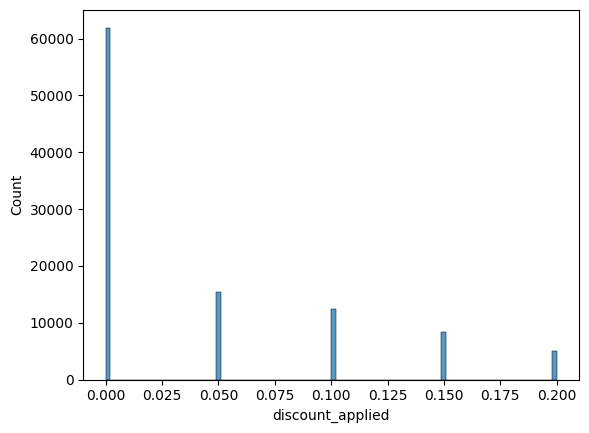

In [74]:
sns.histplot(df4['discount_applied'])
plt.show()

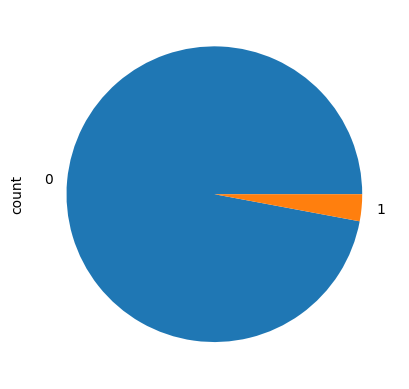

In [75]:
df4['refund_flag'].value_counts().plot(kind='pie')
plt.show()

Adding Campaign 0 Placeholder

In [76]:
print("Events:", (df2['campaign_id'] == 0).sum())
print("Transactions:", (df4['campaign_id'] == 0).sum())

Events: 1000251
Transactions: 20955


In [77]:
print(df['campaign_id'].unique())

[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50]


In [78]:
no_campaign = pd.DataFrame([{
    'campaign_id': 0, 'channel': 'None', 'objective': 'None',
    'start_date': pd.NaT, 'end_date': pd.NaT,
    'target_segment': 'None', 'expected_uplift': 0.0
}])

df = pd.concat([no_campaign, df], ignore_index=True)
df = df.drop_duplicates(subset='campaign_id')

In [79]:
print(df.shape)
print(df.head(3))

(51, 7)
   campaign_id      channel   objective start_date   end_date target_segment  \
0            0         None        None        NaT        NaT           None   
1            1  Paid Search  Cross-sell 2021-10-25 2021-11-26   Deal Seekers   
2            2        Email   Retention 2021-10-24 2021-12-24   Deal Seekers   

   expected_uplift  
0            0.000  
1            0.022  
2            0.116  


Referential Integrity

In [80]:
print(df2['customer_id'].isin(df1['customer_id']).all())
print(df2['product_id'].dropna().isin(df3['product_id']).all())
print(df4['campaign_id'].isin(pd.concat([df['campaign_id'], pd.Series([0])])).all())

True
True
True


Saving all 5 Datasets

In [81]:
df.to_csv('campaigns.csv', index=False)
df1.to_csv('customers.csv', index=False)
df2.to_csv('events.csv', index=False)
df3.to_csv('products.csv', index=False)
df4.to_csv('transactions.csv', index=False)

In [82]:
# Events
df2['customer_id'] = df2['customer_id'].astype('Int64')
df2['product_id'] = df2['product_id'].astype('Int64')
df2['campaign_id'] = df2['campaign_id'].astype('Int64')

# Transactions
df4['customer_id'] = df4['customer_id'].astype('Int64')
df4['product_id'] = df4['product_id'].astype('Int64')
df4['campaign_id'] = df4['campaign_id'].astype('Int64')

# Products
df3['product_id'] = df3['product_id'].astype('Int64')

# Customers
df1['customer_id'] = df1['customer_id'].astype('Int64')

# Campaigns
df['campaign_id'] = df['campaign_id'].astype('Int64')

In [83]:
df.to_csv('campaigns.csv', index=False)
df1.to_csv('customers.csv', index=False)
df2.to_csv('events.csv', index=False)
df3.to_csv('products.csv', index=False)
df4.to_csv('transactions.csv', index=False)